#### 1. Inspect the accounts before comparing outcomes

Start with the rows: one account, its assigned offer, attendance, prior spending, and spending over the next 30 days. Before calling a spending gap causal, check whether attendees were already different.

In [3]:
## data setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

## one row is one account
rng = np.random.default_rng(41)
n = 5000
need = rng.normal(size = n)
prior_bill = 1000 + 150 * need + rng.normal(0, 100, n)
## lottery
offered = rng.binomial(1, 0.5, n) 
would_attend = rng.random(n) < 1 / (1 + np.exp(-0.6 * need))
attended = offered * would_attend

true_effect = -120 ## Known data-setup input, dolars per attending account.
bill = 1000 + 150 * need + true_effect * attended + rng.normal(0, 200, n)
df = pd.DataFrame({'offered': offered, 
                   'attended': attended,
                   'prior_bill': prior_bill,
                   'bill_30d': bill})

In [5]:
print(df.size)
df.head(5)

20000


,offered,attended,prior_bill,bill_30d
0,1,0,872.236887,540.112375
1,1,0,1086.146484,933.882756
2,0,0,1175.803017,1351.034176
3,0,0,855.353917,969.494264
4,0,0,786.990060,326.932270


In [12]:
def difference(values):
    ## Difference by randomized offer, with an independednt-account standard error
    a, b = values[offered == 1], values[offered == 0]
    effect = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof = 1) / len(a) + b.var(ddof = 1) / len(b))
    return effect, se

Raw account rows (amounts in dollars):
 offered  attended  prior_bill  bill_30d
       1         0      872.24    540.11
       1         0     1086.15    933.88
       0         0     1175.80   1351.03
       0         0      855.35    969.49
       0         0      786.99    326.93
       0         0     1030.85    941.80
Raw attendee minus nonattendee spending: $-57.28
Coaching effect set in the data setup: $-120.00


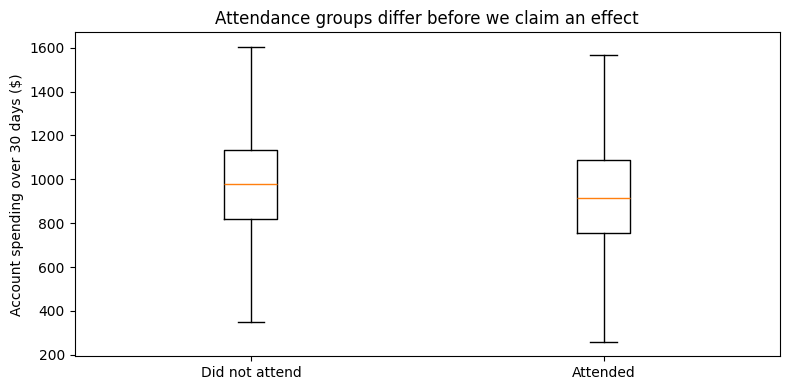

,accounts,prior_bill,bill_30d
Did not attend,3789,984.44,978.06
Attended,1211,1042.10,920.77


In [8]:
# Inspect individual accounts before summarizing. The unobserved need is not in df.
print("Raw account rows (amounts in dollars):")
print(df.head(6).round(2).to_string(index=False))
summary = df.groupby("attended").agg(
    accounts=("bill_30d", "size"),
    prior_bill=("prior_bill", "mean"),
    bill_30d=("bill_30d", "mean"))
summary.index = ["Did not attend", "Attended"]
raw_gap = summary.loc["Attended", "bill_30d"] - summary.loc["Did not attend", "bill_30d"]
print(f"Raw attendee minus nonattendee spending: ${raw_gap:.2f}")
print(f"Coaching effect set in the data setup: ${true_effect:.2f}")

# Show the observed distributions, not just two means.
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([bill[attended == 0], bill[attended == 1]],
           tick_labels=["Did not attend", "Attended"], showfliers=False)
ax.set(ylabel="Account spending over 30 days ($)",
       title="Attendance groups differ before we claim an effect")
plt.tight_layout()
plt.show()
summary.round(2)

With the supplied data, attendees spend $57.28 less than nonattendees. That is not the known $120 coaching effect. The prior-spending column shows that attendance groups were already different: people with greater cost needs are more likely to attend.

The boxplots summarize observed spending, not treatment effects. To get a fairer comparison, return to the lottery groups rather than sorting people by what they chose afterward.

#### 2. Check whether the offer gives us a useful comparison

We need a clear change in attendance, called a strong first stage. Also check that assignment looks balanced before treatment. In a real study, we would audit the lottery logs and compare all important baseline measures; this example checks prior spending.

In [13]:
# Keep ALL applicants in their randomized group, including people who decline.
groups = df.groupby("offered").agg(
    accounts=("bill_30d", "size"),
    attendance_pct=("attended", lambda x: 100 * x.mean()),
    prior_bill=("prior_bill", "mean"),
    bill_30d=("bill_30d", "mean"))
print("Groups defined by the lottery:")
print(groups.round(2).to_string())
first, first_se = difference(attended.astype(float))
prior_gap, prior_se = difference(prior_bill)
# Scale the baseline difference by pooled within-group variability.
prior_sd = np.sqrt((prior_bill[offered == 1].var(ddof=1)
                   + prior_bill[offered == 0].var(ddof=1)) / 2)
smd = prior_gap / prior_sd
print(f"Baseline spending standardized difference: {smd:.4f}")
print("Baseline balance supports the lottery check; it does not prove exclusion.")
pd.DataFrame([
    {"Check": "Attendance increase (percentage points)", "Estimate": 100 * first,
     "95% lower": 100 * (first - 1.96 * first_se),
     "95% upper": 100 * (first + 1.96 * first_se)},
    {"Check": "Prior spending difference ($)", "Estimate": prior_gap,
     "95% lower": prior_gap - 1.96 * prior_se,
     "95% upper": prior_gap + 1.96 * prior_se},
    {"Check": "Robust first-stage Wald F (one instrument)", "Estimate": (first / first_se)**2,
     "95% lower": np.nan, "95% upper": np.nan}
]).round(2)

Groups defined by the lottery:
         accounts  attendance_pct  prior_bill  bill_30d
offered                                                
0            2500            0.00      998.25    991.44
1            2500           48.44      998.56    936.92
Baseline spending standardized difference: 0.0017
Baseline balance supports the lottery check; it does not prove exclusion.


,Check,Estimate,95% lower,95% upper
0,Attendance increase (percentage points),48.44,46.48,50.40
1,Prior spending difference ($),0.31,-9.66,10.28
2,Robust first-stage Wald F (one instrument),2347.78,NaN,NaN


The groups contain 2,500 accounts each. Attendance is 48.44% with an offer and 0% on the waitlist, an increase of 48.44 percentage points. Its 95% interval is about 46.48 to 50.40 points, so the denominator is clearly away from zero.

Prior spending differs by only $0.31, with an interval spanning zero. The standardized difference scales that gap by typical spending variation. These results are consistent with the case-study lottery, not proof that a real offer has no separate effect.

The first-stage F statistic is about 2,348. It summarizes the strength of the attendance change relative to noise. A rule such as “F above 10” is not a certificate of a valid instrument. Here, the large attendance change lets us proceed with a strong-instrument approximation for uncertainty.

#### 3. Estimate both effects and decide what they support

The offer groups spend $ 936.92 vs. $991.44 on average. Subtracting gives the randomized offer effect. Dividing that difference by 0.4844 gives the attendance effect for people induced to attend by the offer.

We also calculate 95% confidence intervals. The IV interval accounts for uncertainty in both the spending difference and the attendance difference. This calculation assumes independent accounts and a strong, valid instrument; it is not a generic two-group t-test on attendees.

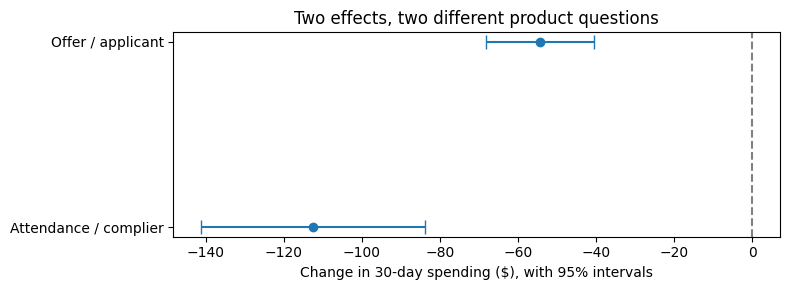

,Effect on 30-day spending,Estimate,Standard error,95% lower,95% upper,p-value (zero effect)
0,Offer: $ per applicant,-54.52,7.05,-68.33,-40.70,1.03e-14
1,Attendance: $ per complier,-112.54,14.63,-141.22,-83.87,1.45e-14


In [14]:
first, first_se = difference(attended.astype(float))
itt, itt_se = difference(bill)
if abs(first) < 1e-8:
    raise ValueError("The offer does not change attendance. IV is undefined.")

# Wald ratio: randomized offer effect divided by its attendance increase.
iv = itt / first
# Delta-method uncertainty accounts for BOTH estimated differences and their covariance.
# Reusing the offer-effect SE, or an ordinary second-stage OLS SE, would be wrong.
_, residual_se = difference(bill - iv * attended)
iv_se = residual_se / abs(first)
rows = []
for name, effect, se in [
    ("Offer: $ per applicant", itt, itt_se),
    ("Attendance: $ per complier", iv, iv_se)
]:
    rows.append({"Effect on 30-day spending": name,
                 "Estimate": effect, "Standard error": se,
                 "95% lower": effect - 1.96 * se,
                 "95% upper": effect + 1.96 * se,
                 "p-value (zero effect)": 2 * norm.sf(abs(effect / se))})
result = pd.DataFrame(rows)
# Lower spending is a negative effect. Show the interval and zero reference together.
fig, ax = plt.subplots(figsize=(8, 3))
ax.errorbar(result["Estimate"], [1, 0],
            xerr=1.96 * result["Standard error"], fmt="o", capsize=5)
ax.axvline(0, color="gray", linestyle="--")
ax.set(yticks=[1, 0], yticklabels=["Offer / applicant", "Attendance / complier"],
       xlabel="Change in 30-day spending ($), with 95% intervals",
       title="Two effects, two different product questions")
plt.tight_layout()
plt.show()
# Format tiny p-values explicitly rather than rounding them to zero.
result["p-value (zero effect)"] = result["p-value (zero effect)"].map(lambda p: f"{p:.2e}")
result.round(2)

What did we find? Offering a seat reduces spending by about $54.52 per applicant over 30 days. Its 95% interval runs from a $40.70 to $68.33 reduction. This is the effect of the seat-offer strategy across everyone offered a seat, including people who decline.

Attending reduces spending by an estimated $112.54 per complier, with a 95% interval from an $83.87 to $141.22 reduction. The interval includes the $120 effect set in the data setup. These estimates differ because only about half of offered accounts attend.

How sure are we? Both p-values are below 0.001, against a prespecified 5% significance level. The data provide evidence against zero effects under the stated assumptions. Small p-values do not establish that the invitation works only through attendance.

What would I recommend? The offer is promising for this applicant population. Before adding seats, compare delivery costs with customer savings and check workload completion, reliability, and customer satisfaction. Those guardrails are not measured here. Keep the lottery in a larger pilot if these checks pass; do not promise every cloud customer a $112.54 benefit.